# 1: Imports

In [1]:
import sys
sys.path.append("..")

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from PIL import Image

from src.config import *
from src.data_utils import *

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# 2: Preprocessing demo (resize and normalize on one image)

Original   : shape=(640, 640, 3), min=0, max=255
Resized    : shape=(224, 224, 3)
Normalized : min=0.00, max=0.96


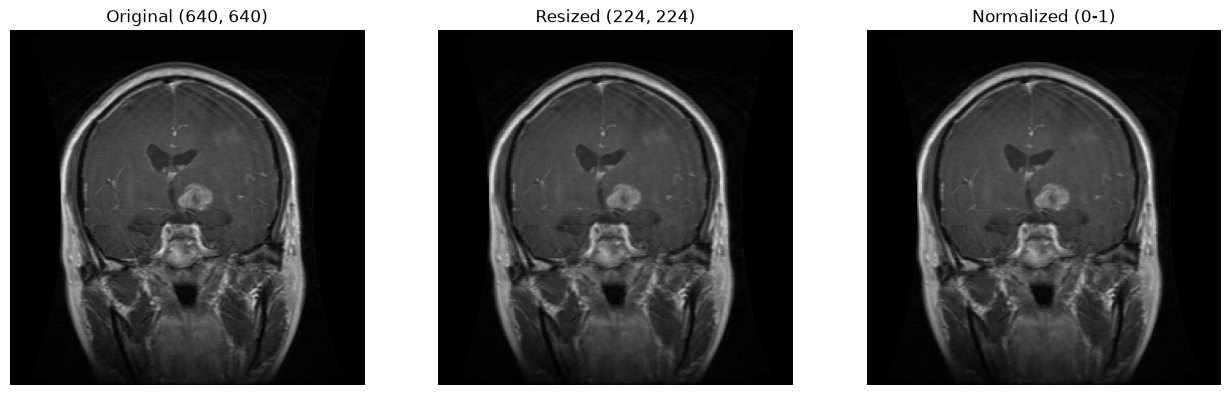

In [2]:
sample_path = random.choice(list_images(TRAIN_DIR / "glioma"))
orig = np.array(Image.open(sample_path).convert("RGB"))
resized = tf.image.resize(orig, IMG_SIZE).numpy()
normalized = resized / 255.0

print(f"Original   : shape={orig.shape}, min={orig.min()}, max={orig.max()}")
print(f"Resized    : shape={resized.shape}")
print(f"Normalized : min={normalized.min():.2f}, max={normalized.max():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(orig);                        ax[0].set_title(f"Original {orig.shape[:2]}")
ax[1].imshow(resized.astype("uint8"));     ax[1].set_title(f"Resized {IMG_SIZE}")
ax[2].imshow(normalized);                  ax[2].set_title("Normalized (0-1)")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_preprocessing_demo.png", dpi=150)
plt.show()

# 3: Individual augmentation effects

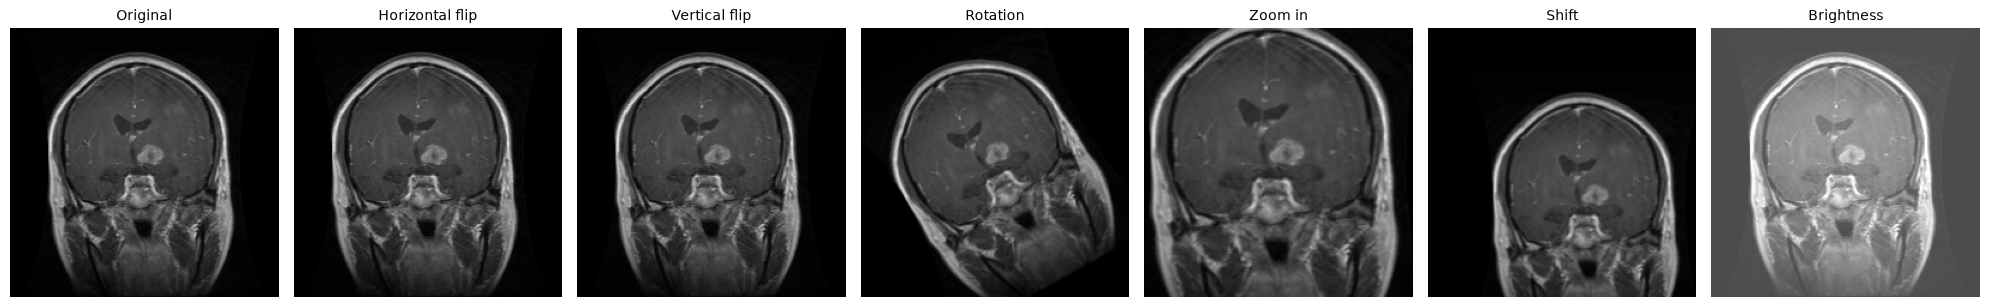

In [3]:
img = tf.expand_dims(resized.astype("float32"), 0)   # add batch dimension

# Stronger settings than training, so the effect is easy to see
demo_layers = {
    "Original":        None,
    "Horizontal flip": keras.layers.RandomFlip("horizontal"),
    "Vertical flip":   keras.layers.RandomFlip("vertical"),
    "Rotation":        keras.layers.RandomRotation((0.08, 0.08), fill_mode="constant"),
    "Zoom in":         keras.layers.RandomZoom((-0.25, -0.25), fill_mode="constant"),
    "Shift":           keras.layers.RandomTranslation((0.15, 0.15), (0.1, 0.1), fill_mode="constant"),
    "Brightness":      keras.layers.RandomBrightness((0.3, 0.3), value_range=(0, 255)),
}

fig, axes = plt.subplots(1, len(demo_layers), figsize=(20, 3.5))
for ax, (name, layer) in zip(axes, demo_layers.items()):
    out = img if layer is None else layer(img, training=True)
    ax.imshow(out[0].numpy().astype("uint8"))
    ax.set_title(name, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_augmentation_individual.png", dpi=150)
plt.show()

# 4: Combined random augmentation (what training actually uses)

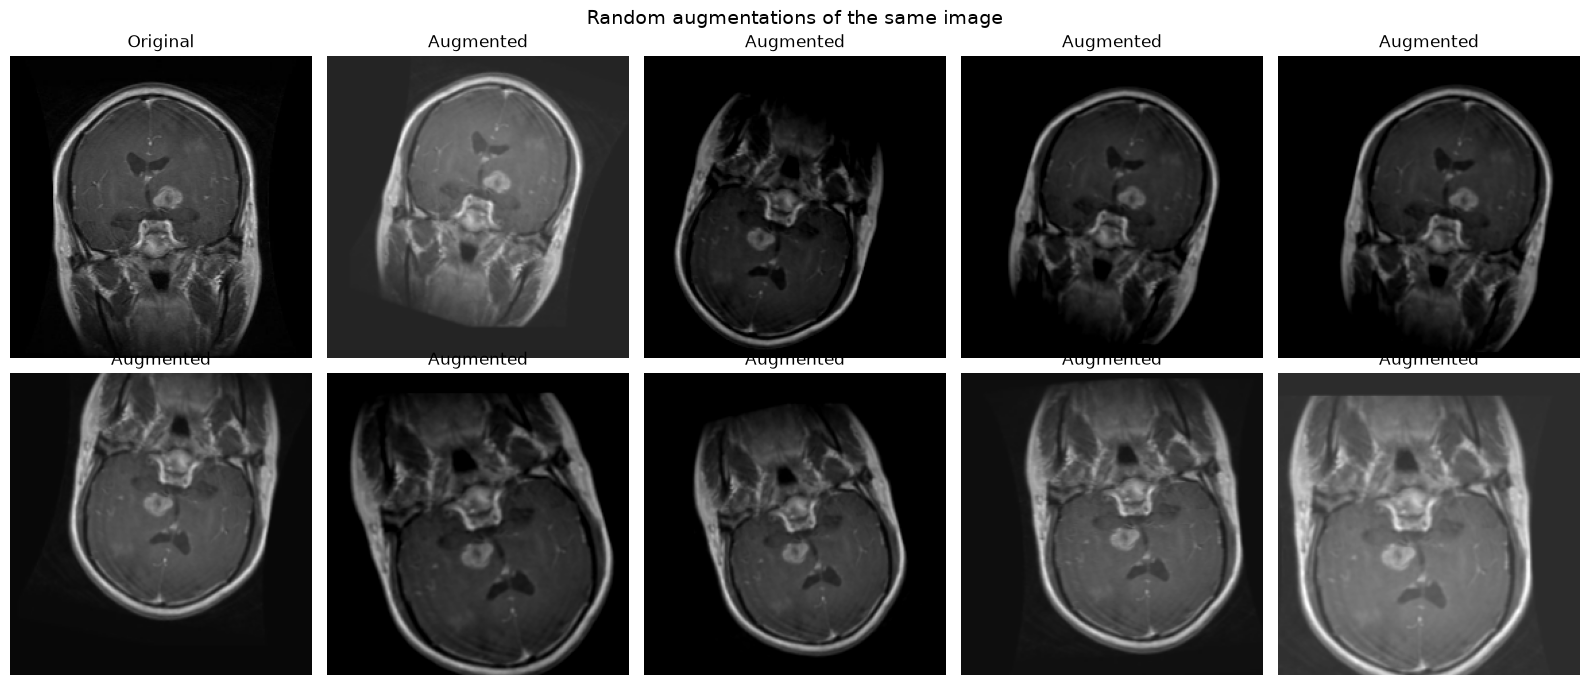

In [4]:
aug = build_augmentation()

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes[0, 0].imshow(resized.astype("uint8")); axes[0, 0].set_title("Original"); axes[0, 0].axis("off")
for ax in axes.flat[1:]:
    out = aug(img, training=True)[0].numpy().astype("uint8")
    ax.imshow(out); ax.set_title("Augmented"); ax.axis("off")
plt.suptitle("Random augmentations of the same image", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_augmentation_combined.png", dpi=150)
plt.show()

# 5: Build the final datasets

In [5]:
train_ds, val_ds, test_ds = get_datasets()

Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Found 246 files belonging to 4 classes.


# 6: Verify shapes, labels and the 0-1 range

In [6]:
x_batch, y_batch = next(iter(train_ds))
print("Image batch:", x_batch.shape, x_batch.dtype)
print("Label batch:", y_batch.shape)
print(f"Pixel range: {x_batch.numpy().min():.3f} to {x_batch.numpy().max():.3f}")

xv, _ = next(iter(val_ds))
print(f"Validation pixel range: {xv.numpy().min():.3f} to {xv.numpy().max():.3f}")

print("Steps per epoch (train):", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

Image batch: (32, 224, 224, 3) <dtype: 'float32'>
Label batch: (32, 4)
Pixel range: 0.000 to 1.000
Validation pixel range: 0.000 to 0.994
Steps per epoch (train): 53 | val: 16 | test: 8


# 7: Look at a real training batch

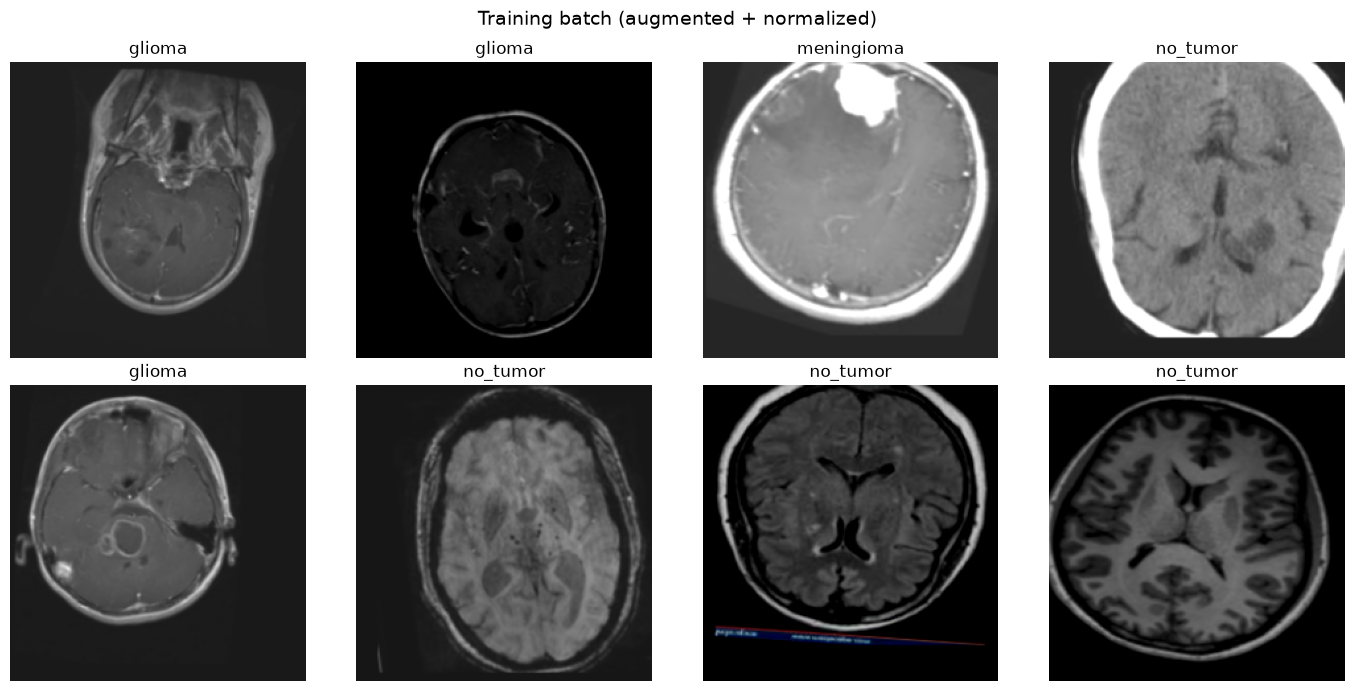

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img_, lbl in zip(axes.flat, x_batch.numpy(), y_batch.numpy()):
    ax.imshow(img_)
    ax.set_title(CLASS_NAMES[lbl.argmax()])
    ax.axis("off")
plt.suptitle("Training batch (augmented + normalized)", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_training_batch.png", dpi=150)
plt.show()

## Preprocessing and Augmentation Summary
- Resize: 640x640 -> 224x224

- Normalization: pixel values scaled to 0-1 (Rescaling 1/255)

- Augmentation (training only): horizontal/vertical flip, rotation (~±18°), zoom (±15%), shifts (±10%), brightness (±20%)

- Validation and test sets: resize + normalize only, no augmentation, test not shuffled

- Class imbalance handled with class weights